In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier

In [95]:
df = pd.read_csv("ai4i2020.csv")

In [97]:
df.shape

(10000, 14)

In [98]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')

In [99]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [100]:
df.dtypes
df.nunique
df["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [101]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [102]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [103]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

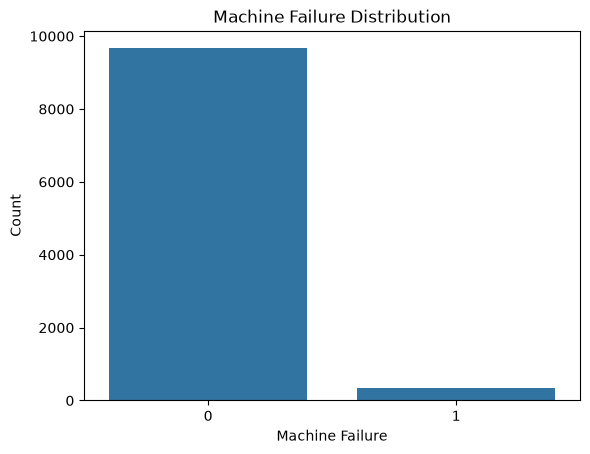

In [104]:
sns.countplot(data=df, x="Machine failure")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.show()

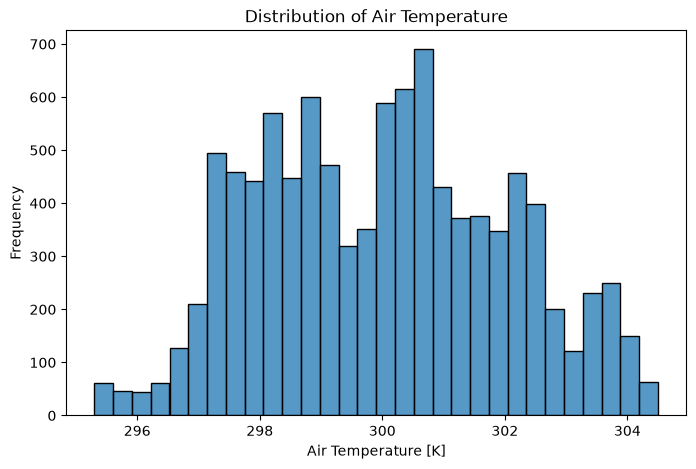

In [105]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Air temperature [K]", bins=30)

plt.title("Distribution of Air Temperature")
plt.xlabel("Air Temperature [K]")
plt.ylabel("Frequency")

plt.show()

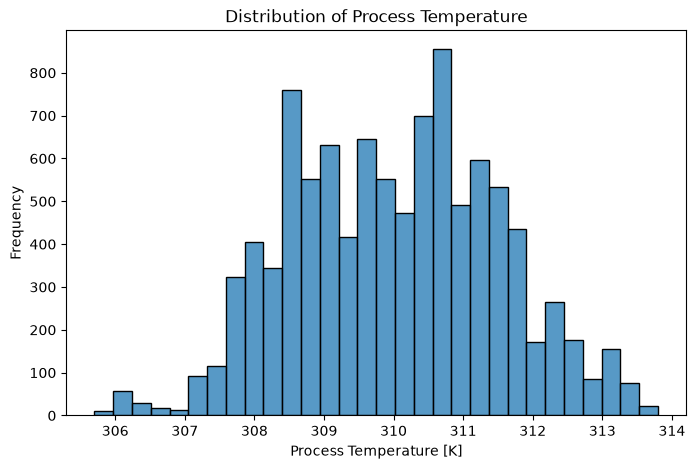

In [106]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Process temperature [K]", bins=30)

plt.title("Distribution of Process Temperature")
plt.xlabel("Process Temperature [K]")
plt.ylabel("Frequency")

plt.show()

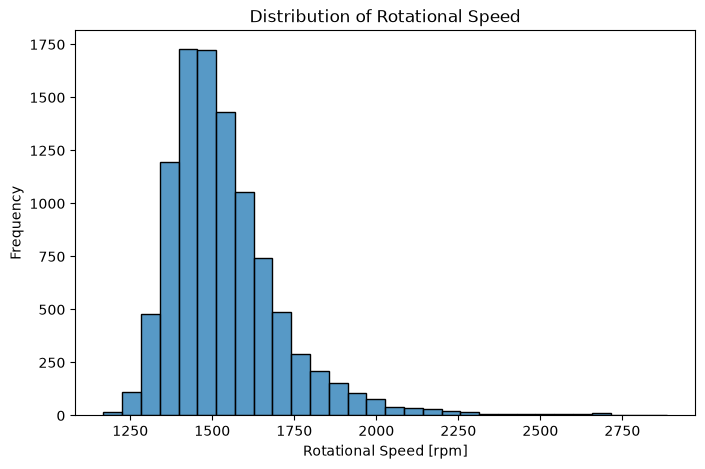

In [107]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Rotational speed [rpm]", bins=30)

plt.title("Distribution of Rotational Speed")
plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Frequency")

plt.show()

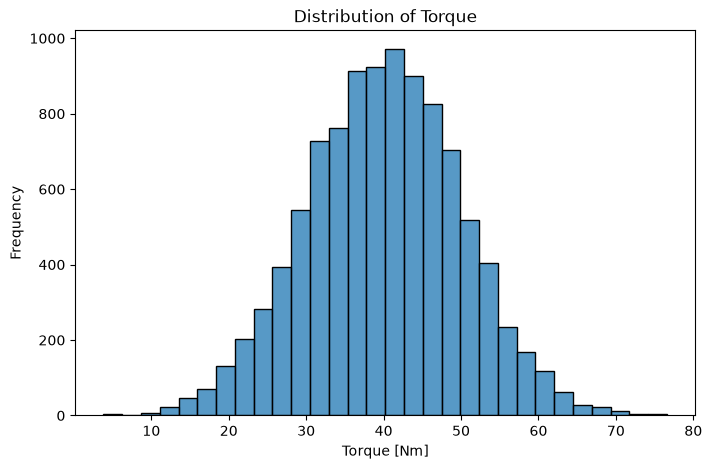

In [108]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Torque [Nm]", bins=30)

plt.title("Distribution of Torque")
plt.xlabel("Torque [Nm]")
plt.ylabel("Frequency")

plt.show()

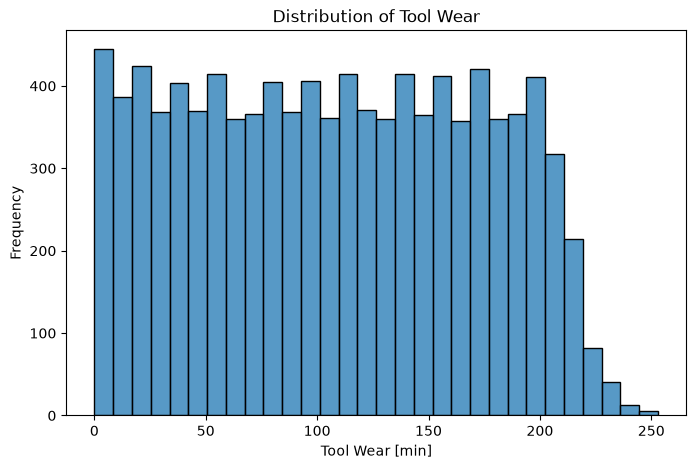

In [109]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Tool wear [min]", bins=30)

plt.title("Distribution of Tool Wear")
plt.xlabel("Tool Wear [min]")
plt.ylabel("Frequency")

plt.show()

In [110]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [111]:
df["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

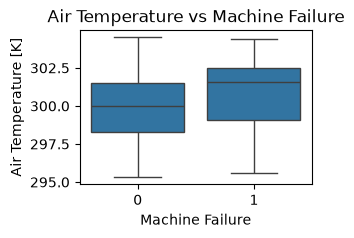

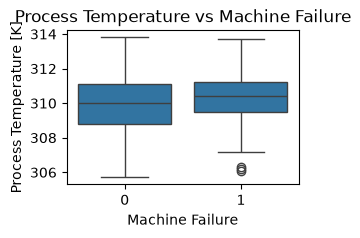

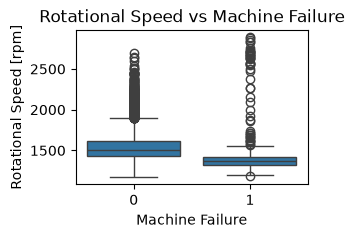

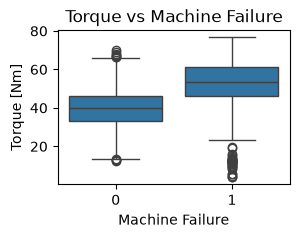

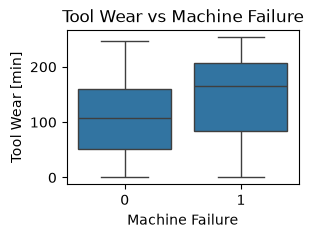

In [112]:
plt.figure(figsize=(3, 2))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Air temperature [K]"
)

plt.title("Air Temperature vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Air Temperature [K]")

plt.show()

plt.figure(figsize=(3, 2))
sns.boxplot(
    data=df,
    x="Machine failure",
    y="Process temperature [K]"
)
plt.title("Process Temperature vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Process Temperature [K]")
plt.show()
plt.figure(figsize=(3, 2))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Rotational speed [rpm]"
)

plt.title("Rotational Speed vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Rotational Speed [rpm]")

plt.show()

plt.figure(figsize=(3, 2))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Torque [Nm]"
)

plt.title("Torque vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Torque [Nm]")

plt.show()

plt.figure(figsize=(3, 2))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Tool wear [min]"
)

plt.title("Tool Wear vs Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Tool Wear [min]")

plt.show()

In [113]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df.groupby("Machine failure")[features].median().T


Machine failure,0,1
Air temperature [K],300.0,301.6
Process temperature [K],310.0,310.4
Rotational speed [rpm],1507.0,1365.0
Torque [Nm],39.9,53.7
Tool wear [min],107.0,165.0


In [114]:
df.groupby("Machine failure")[features].mean().T

Machine failure,0,1
Air temperature [K],299.973999,300.886431
Process temperature [K],309.995570,310.290265
Rotational speed [rpm],1540.260014,1496.486726
Torque [Nm],39.629655,50.168142
Tool wear [min],106.693717,143.781711


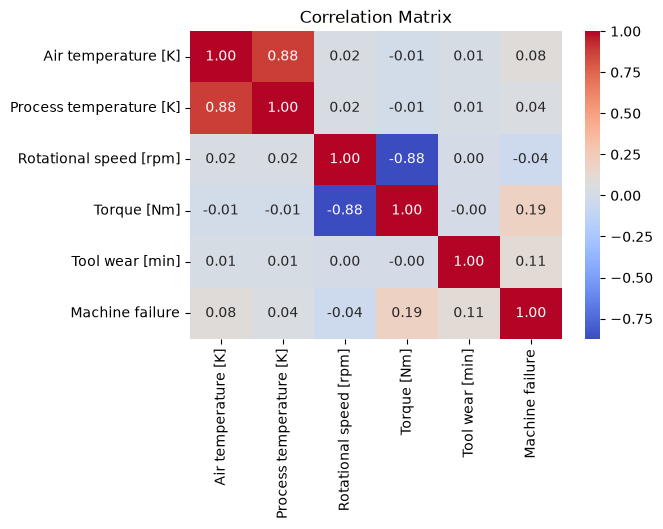

In [115]:
plt.figure(figsize=(6, 4))

corr = df[features + ["Machine failure"]].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [116]:
def find_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]

    return Q1, Q3, IQR, lower, upper, len(outliers)

In [117]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for col in numerical_features:
    result = find_outliers_iqr(df, col)

    print("\n", col)
    print("Q1:", result[0])
    print("Q3:", result[1])
    print("IQR:", result[2])
    print("Lower:", result[3])
    print("Upper:", result[4])
    print("Potential outliers:", result[5])


 Air temperature [K]
Q1: 298.3
Q3: 301.5
IQR: 3.1999999999999886
Lower: 293.5
Upper: 306.29999999999995
Potential outliers: 0

 Process temperature [K]
Q1: 308.8
Q3: 311.1
IQR: 2.3000000000000114
Lower: 305.35
Upper: 314.55000000000007
Potential outliers: 0

 Rotational speed [rpm]
Q1: 1423.0
Q3: 1612.0
IQR: 189.0
Lower: 1139.5
Upper: 1895.5
Potential outliers: 418

 Torque [Nm]
Q1: 33.2
Q3: 46.8
IQR: 13.599999999999994
Lower: 12.800000000000011
Upper: 67.19999999999999
Potential outliers: 69

 Tool wear [min]
Q1: 53.0
Q3: 162.0
IQR: 109.0
Lower: -110.5
Upper: 325.5
Potential outliers: 0


In [118]:
rot_speed_outliers = df[
    (df["Rotational speed [rpm]"] < 1139.5) |
    (df["Rotational speed [rpm]"] > 1895.5)
]

rot_speed_outliers[[
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
    "Machine failure"
]].head(20)

,Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
14,2035,19.6,40,0
50,2861,4.6,143,1
70,1924,22.6,193,0
101,1991,20.7,59,0
155,1987,19.8,198,0
172,1924,20.8,29,0
177,1988,21.4,41,0
194,2678,10.7,86,1
267,1954,21.1,42,0
284,2051,19.2,90,0


In [119]:
torque_outliers = df[
    (df["Torque [Nm]"] < 12.8) |
    (df["Torque [Nm]"] > 67.2)
]

torque_outliers[[
    "Torque [Nm]",
    "Rotational speed [rpm]",
    "Tool wear [min]",
    "Machine failure"
]].head(20)

,Torque [Nm],Rotational speed [rpm],Tool wear [min],Machine failure
50,4.6,2861,143,1
194,10.7,2678,86,1
463,4.2,2874,118,1
603,71.6,1336,31,1
847,5.6,2833,213,1
880,76.2,1235,89,1
1016,68.3,1319,24,1
1095,9.3,2721,18,1
1124,69.0,1258,105,1
1144,69.1,1296,153,1


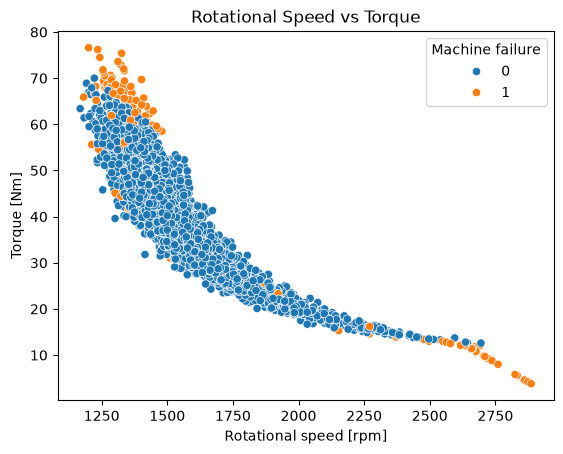

In [120]:
sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure"
)

plt.title("Rotational Speed vs Torque")
plt.show()

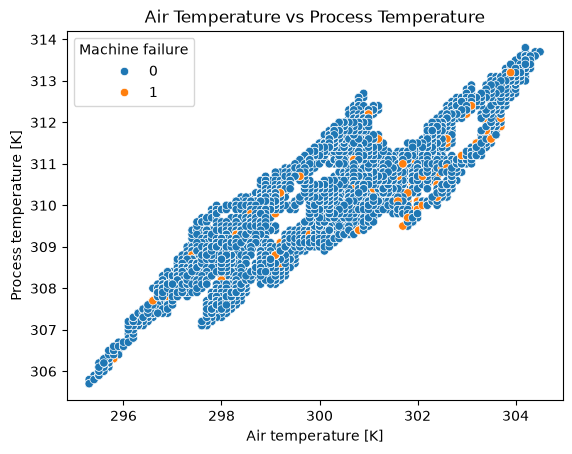

In [121]:
sns.scatterplot(
    data=df,
    x="Air temperature [K]",
    y="Process temperature [K]",
    hue="Machine failure"
)

plt.title("Air Temperature vs Process Temperature")
plt.show()

In [122]:
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
X = df[features]
y = df["Machine failure"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX columns:")
print(X.columns.tolist())

print("\ny distribution:")
print(y.value_counts())

X shape: (10000, 5)
y shape: (10000,)

X columns:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

y distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [123]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train: (8000, 5)
X_test: (2000, 5)
y_train: (8000,)
y_test: (2000,)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [124]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [125]:
print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(X_train_scaled[:5])

Before scaling:
      Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
4058                302.0                    310.9                    1456   
1221                297.0                    308.3                    1399   
6895                301.0                    311.6                    1357   
9863                298.9                    309.8                    1411   
8711                297.1                    308.5                    1733   

      Torque [Nm]  Tool wear [min]  
4058         47.2               54  
1221         46.4              132  
6895         45.6              137  
9863         56.3               84  
8711         28.7               50  

After scaling:
[[ 0.99891359  0.60428162 -0.46060741  0.71830476 -0.84399726]
 [-1.50519408 -1.15325984 -0.77557391  0.63845583  0.38226308]
 [ 0.49809206  1.07746586 -1.00765448  0.5586069   0.46086951]
 [-0.55363316 -0.13929361 -0.70926517  1.62658635 -0.37235867]
 [-1.45511192 -1.01806434

In [126]:
log_reg = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    max_iter=1000
)

In [127]:
log_reg.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [128]:
y_pred = log_reg.predict(X_test_scaled)
y_prob = log_reg.predict_proba(X_test_scaled)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 failure probabilities:")
print(y_prob[:10, 1])

First 10 predictions:
[1 0 1 0 1 1 1 0 0 0]

First 10 failure probabilities:
[0.96725355 0.49638428 0.64496584 0.01377921 0.89024043 0.70775131
 0.74562175 0.16679653 0.03501345 0.47108294]


In [129]:
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": log_reg.coef_[0]
})

coefficients

,Feature,Coefficient
0,Air temperature [K],1.748740
1,Process temperature [K],-1.198877
2,Rotational speed [rpm],1.735670
3,Torque [Nm],2.420522
4,Tool wear [min],0.872298


In [130]:
print("Intercept:", log_reg.intercept_[0])

Intercept: -1.4552457898477706


[[1585  347]
 [  11   57]]


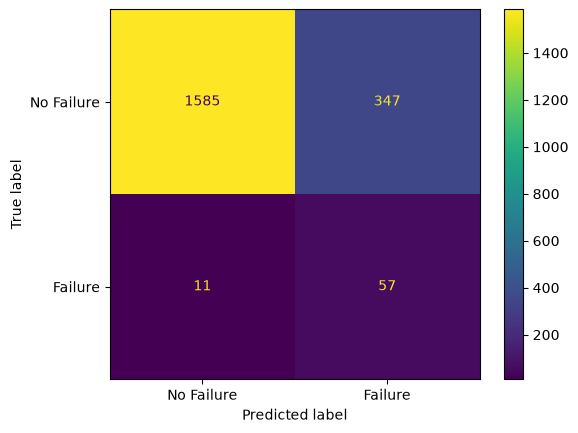

In [131]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot()
plt.show()

In [132]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.14108910891089108
Recall: 0.8382352941176471
F1 Score: 0.24152542372881355


In [133]:
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(y_test, y_prob[:, 1])

print("ROC-AUC:", auc)

ROC-AUC: 0.907974059188893


In [134]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)

[[1913   19]
 [  21   47]]


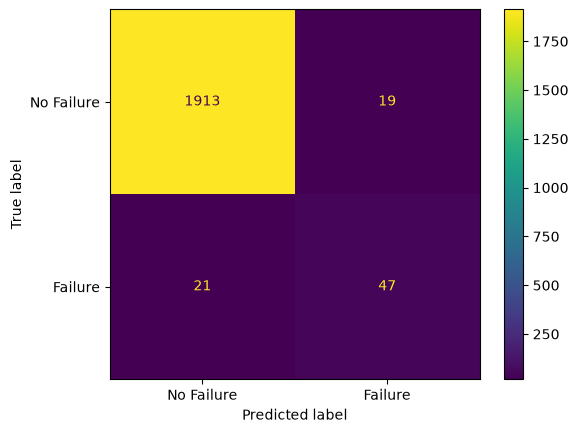

In [135]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

print(cm_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No Failure", "Failure"]
)

disp.plot()
plt.show()

In [136]:
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Precision:", precision_rf)
print("Recall:", recall_rf)
print("F1 Score:", f1_rf)

Precision: 0.7121212121212122
Recall: 0.6911764705882353
F1 Score: 0.7014925373134329


In [137]:
auc_rf = roc_auc_score(y_test, y_prob_rf[:, 1])

print("ROC-AUC:", auc_rf)

ROC-AUC: 0.9632352941176472


In [138]:
import xgboost as xgb

In [139]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=28.5,
    random_state=42,
    eval_metric="logloss"
)

In [140]:
X_train_xgb = X_train.copy()
X_test_xgb = X_test.copy()

X_train_xgb.columns = [
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear"
]

X_test_xgb.columns = X_train_xgb.columns

In [141]:
xgb_model.fit(X_train_xgb, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [142]:
y_pred_xgb = xgb_model.predict(X_test_xgb)
y_prob_xgb = xgb_model.predict_proba(X_test_xgb)

[[1794  138]
 [   8   60]]


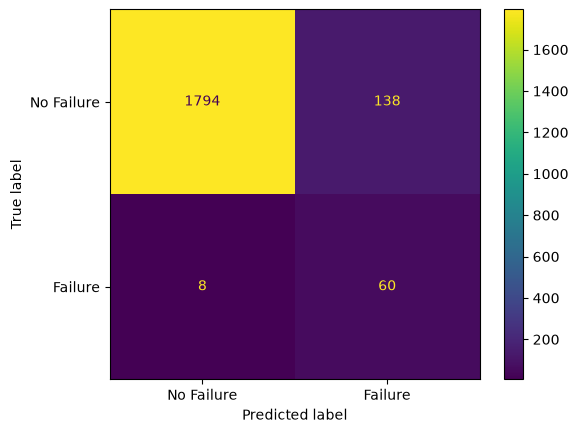

In [143]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

print(cm_xgb)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["No Failure", "Failure"]
)

disp.plot()
plt.show()

In [144]:
precision_xgb = precision_score(y_test, y_pred_xgb)
recall_xgb = recall_score(y_test, y_pred_xgb)
f1_xgb = f1_score(y_test, y_pred_xgb)

print("Precision:", precision_xgb)
print("Recall:", recall_xgb)
print("F1 Score:", f1_xgb)
auc_xgb = roc_auc_score(y_test, y_prob_xgb[:, 1])

print("ROC-AUC:", auc_xgb)

Precision: 0.30303030303030304
Recall: 0.8823529411764706
F1 Score: 0.45112781954887216
ROC-AUC: 0.9684417245158933


In [145]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    xgb_model,
    X_train_xgb,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("CV ROC-AUC scores:", cv_scores)
print("Mean CV ROC-AUC:", cv_scores.mean())
print("Std CV ROC-AUC:", cv_scores.std())

CV ROC-AUC scores: [0.98646447 0.97576781 0.95335633 0.98253558 0.96562518]
Mean CV ROC-AUC: 0.9727498750678896
Std CV ROC-AUC: 0.011998573255841988


In [146]:
for depth in [2, 3, 4, 5]:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=depth,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=28.5,
        random_state=42,
        eval_metric="logloss"
    )

    scores = cross_val_score(
        model,
        X_train_xgb,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"max_depth={depth} | "
        f"Mean ROC-AUC={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )

max_depth=2 | Mean ROC-AUC=0.9672 | Std=0.0141
max_depth=3 | Mean ROC-AUC=0.9727 | Std=0.0120
max_depth=4 | Mean ROC-AUC=0.9719 | Std=0.0123
max_depth=5 | Mean ROC-AUC=0.9723 | Std=0.0108


In [147]:
for lr in [0.03, 0.05, 0.10, 0.20]:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=lr,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=28.5,
        random_state=42,
        eval_metric="logloss"
    )

    scores = cross_val_score(
        model,
        X_train_xgb,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"learning_rate={lr} | "
        f"Mean ROC-AUC={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )

learning_rate=0.03 | Mean ROC-AUC=0.9669 | Std=0.0138
learning_rate=0.05 | Mean ROC-AUC=0.9703 | Std=0.0129
learning_rate=0.1 | Mean ROC-AUC=0.9727 | Std=0.0120
learning_rate=0.2 | Mean ROC-AUC=0.9712 | Std=0.0118


In [149]:
for n in [50, 100, 200, 300]:

    model = XGBClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=28.5,
        random_state=42,
        eval_metric="logloss"
    )

    scores = cross_val_score(
        model,
        X_train_xgb,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"n_estimators={n} | "
        f"Mean ROC-AUC={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )

n_estimators=50 | Mean ROC-AUC=0.9697 | Std=0.0126
n_estimators=100 | Mean ROC-AUC=0.9727 | Std=0.0120
n_estimators=200 | Mean ROC-AUC=0.9718 | Std=0.0101
n_estimators=300 | Mean ROC-AUC=0.9705 | Std=0.0106


In [150]:
for subsample in [0.6, 0.8, 1.0]:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=subsample,
        colsample_bytree=0.8,
        scale_pos_weight=28.5,
        random_state=42,
        eval_metric="logloss"
    )

    scores = cross_val_score(
        model,
        X_train_xgb,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"subsample={subsample} | "
        f"Mean ROC-AUC={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )

subsample=0.6 | Mean ROC-AUC=0.9707 | Std=0.0118
subsample=0.8 | Mean ROC-AUC=0.9727 | Std=0.0120
subsample=1.0 | Mean ROC-AUC=0.9714 | Std=0.0128


In [151]:
for colsample in [0.6, 0.8, 1.0]:

    model = XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=colsample,
        scale_pos_weight=28.5,
        random_state=42,
        eval_metric="logloss"
    )

    scores = cross_val_score(
        model,
        X_train_xgb,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    print(
        f"colsample_bytree={colsample} | "
        f"Mean ROC-AUC={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )

colsample_bytree=0.6 | Mean ROC-AUC=0.9703 | Std=0.0126
colsample_bytree=0.8 | Mean ROC-AUC=0.9727 | Std=0.0120
colsample_bytree=1.0 | Mean ROC-AUC=0.9728 | Std=0.0109


In [152]:
xgb_tuned = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=28.5,
    random_state=42,
    eval_metric="logloss"
)

xgb_tuned.fit(X_train_xgb, y_train)

y_pred_tuned = xgb_tuned.predict(X_test_xgb)
y_prob_tuned = xgb_tuned.predict_proba(X_test_xgb)

[[1794  138]
 [   7   61]]


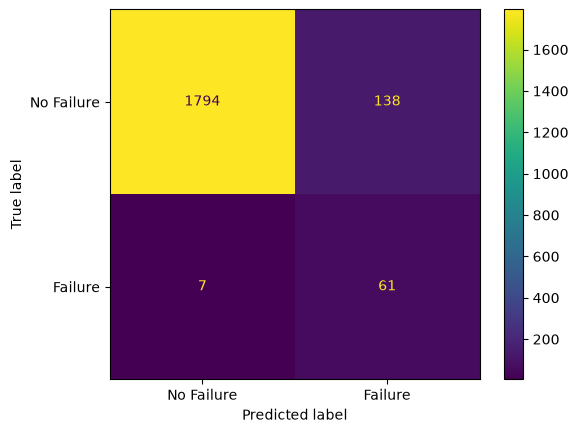

In [153]:
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

print(cm_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=["No Failure", "Failure"]
)

disp.plot()
plt.show()

In [154]:
precision_tuned = precision_score(y_test, y_pred_tuned)
recall_tuned = recall_score(y_test, y_pred_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_prob_tuned[:, 1])

print("Precision:", precision_tuned)
print("Recall:", recall_tuned)
print("F1 Score:", f1_tuned)
print("ROC-AUC:", auc_tuned)

Precision: 0.3065326633165829
Recall: 0.8970588235294118
F1 Score: 0.45692883895131087
ROC-AUC: 0.9681296431616124


In [155]:
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob_tuned[:, 1] >= threshold).astype(int)

    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"Threshold={threshold} | "
        f"Precision={precision:.4f} | "
        f"Recall={recall:.4f} | "
        f"F1={f1:.4f}"
    )

Threshold=0.2 | Precision=0.2100 | Recall=0.9265 | F1=0.3424
Threshold=0.3 | Precision=0.2395 | Recall=0.9265 | F1=0.3807
Threshold=0.4 | Precision=0.2696 | Recall=0.9118 | F1=0.4161
Threshold=0.5 | Precision=0.3065 | Recall=0.8971 | F1=0.4569
Threshold=0.6 | Precision=0.3491 | Recall=0.8676 | F1=0.4979
Threshold=0.7 | Precision=0.4275 | Recall=0.8676 | F1=0.5728


In [156]:
from sklearn.metrics import precision_recall_curve
precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_tuned[:, 1]
)

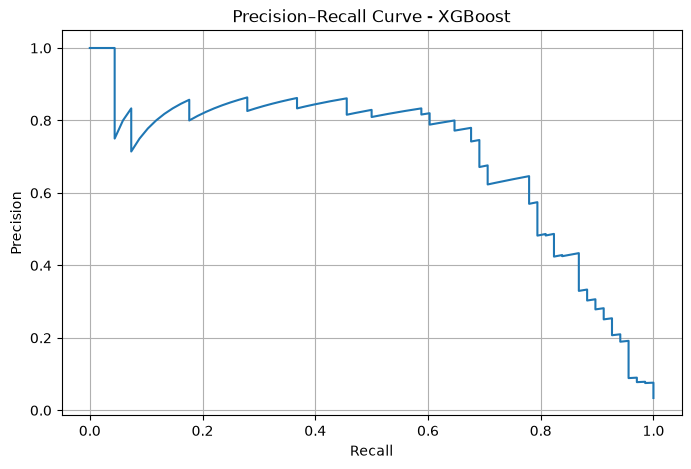

In [157]:
plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve - XGBoost")

plt.grid(True)
plt.show()

In [158]:
threshold = 0.7

y_pred_07 = (y_prob_tuned[:, 1] >= threshold).astype(int)

print("Predicted failures:", y_pred_07.sum())
print("Actual failures:", y_test.sum())

Predicted failures: 138
Actual failures: 68


In [159]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_07)

print(cm)

[[1853   79]
 [   9   59]]


In [160]:
feature_importance = pd.DataFrame({
    "Feature": X_train_xgb.columns,
    "Importance": xgb_tuned.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
2,rotational_speed,0.285978
3,torque,0.264157
4,tool_wear,0.243027
0,air_temperature,0.142679
1,process_temperature,0.064160


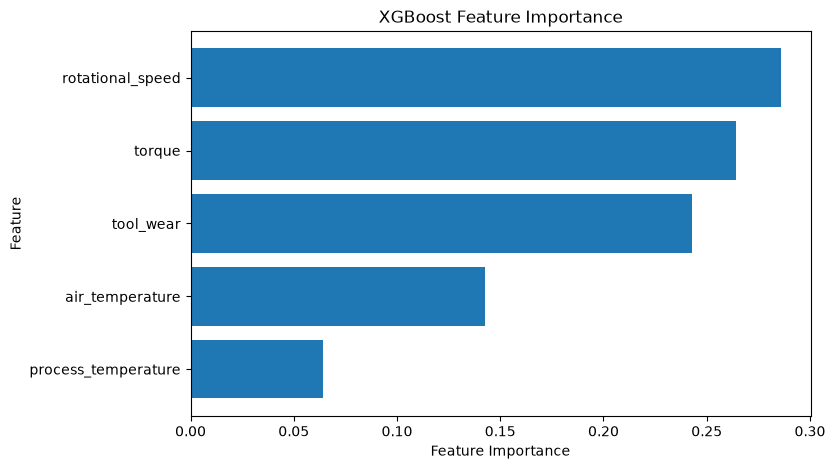

In [161]:
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")

plt.gca().invert_yaxis()

plt.show()

In [162]:
from sklearn.ensemble import IsolationForest


# Use the same five sensor features
features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Train Isolation Forest only on normal training observations
X_train_normal = X_train[y_train == 0]

iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42
)

iso_forest.fit(X_train_normal)

# Predict anomalies on the test set
anomaly_pred = iso_forest.predict(X_test)

# Convert Isolation Forest output:
# 1  = Normal
# -1 = Anomaly
anomaly_flag = (anomaly_pred == -1).astype(int)

# 0 = Normal, 1 = Anomaly
print("Anomaly counts:")
print(pd.Series(anomaly_flag).value_counts())

# Compare detected anomalies with actual machine failures
comparison = pd.crosstab(
    anomaly_flag,
    y_test,
    rownames=["Predicted Anomaly"],
    colnames=["Actual Machine Failure"]
)

print("\nAnomaly vs Actual Failure:")
print(comparison)

Anomaly counts:
0    1940
1      60
Name: count, dtype: int64

Anomaly vs Actual Failure:
Actual Machine Failure     0   1
Predicted Anomaly               
0                       1882  58
1                         50  10


In [163]:
# Get XGBoost failure probability
failure_probability = y_prob_tuned[:, 1]

# Get Isolation Forest anomaly score
# Higher score = more normal
# Lower score = more anomalous
anomaly_score = iso_forest.decision_function(X_test)

# Create a maintenance insights table
maintenance_insights = X_test.copy()

maintenance_insights["Actual Failure"] = y_test.values
maintenance_insights["Failure Probability"] = failure_probability
maintenance_insights["Anomaly Score"] = anomaly_score
maintenance_insights["Anomaly"] = anomaly_flag

# Create a combined maintenance interpretation
def maintenance_status(row):
    if row["Failure Probability"] >= 0.7 and row["Anomaly"] == 1:
        return "High Concern"
    elif row["Failure Probability"] >= 0.7:
        return "Predicted Failure"
    elif row["Anomaly"] == 1:
        return "Unusual Behavior"
    else:
        return "Normal"

maintenance_insights["Maintenance Status"] = maintenance_insights.apply(
    maintenance_status,
    axis=1
)

# Display first 10 records
print(maintenance_insights.head(10))

# Count each maintenance status
print("\nMaintenance Status Counts:")
print(maintenance_insights["Maintenance Status"].value_counts())

      Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
2997                300.5                    309.8                    1345   
4871                303.7                    312.4                    1513   
3858                302.5                    311.4                    1559   
951                 295.6                    306.3                    1509   
6463                300.5                    310.0                    1358   
3264                301.3                    310.1                    1455   
4508                302.4                    310.0                    1426   
2100                299.3                    309.3                    1471   
7885                300.7                    312.3                    1590   
2421                298.9                    308.2                    2384   

      Torque [Nm]  Tool wear [min]  Actual Failure  Failure Probability  \
2997         62.7              153               0             0.8

In [164]:
# ==============================
# FEATURE ENGINEERING
# ==============================

import pandas as pd

# Start with the original five sensor features
X_engineered = X.copy()

# 1. Temperature difference
# Difference between process and air temperature
X_engineered["temperature_difference"] = (
    X_engineered["Process temperature [K]"]
    - X_engineered["Air temperature [K]"]
)

# 2. Mechanical power proxy
# Power is related to torque × rotational speed
X_engineered["mechanical_power_proxy"] = (
    X_engineered["Torque [Nm]"]
    * X_engineered["Rotational speed [rpm]"]
)

# 3. Temperature ratio
X_engineered["temperature_ratio"] = (
    X_engineered["Process temperature [K]"]
    / X_engineered["Air temperature [K]"]
)

# 4. Torque-to-speed ratio
# Captures the relationship between load and rotational speed
X_engineered["torque_speed_ratio"] = (
    X_engineered["Torque [Nm]"]
    / X_engineered["Rotational speed [rpm]"]
)

# 5. Wear-temperature interaction
# Captures combined effect of tool wear and temperature difference
X_engineered["wear_temperature_interaction"] = (
    X_engineered["Tool wear [min]"]
    * X_engineered["temperature_difference"]
)

# Check the new features
print("Original shape:", X.shape)
print("Engineered shape:", X_engineered.shape)

print("\nNew features:")
print(X_engineered.head())

print("\nFeature names:")
print(X_engineered.columns.tolist())

Original shape: (10000, 5)
Engineered shape: (10000, 10)

New features:
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.1                    308.6                    1551   
1                298.2                    308.7                    1408   
2                298.1                    308.5                    1498   
3                298.2                    308.6                    1433   
4                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  temperature_difference  \
0         42.8                0                    10.5   
1         46.3                3                    10.5   
2         49.4                5                    10.4   
3         39.5                7                    10.4   
4         40.0                9                    10.5   

   mechanical_power_proxy  temperature_ratio  torque_speed_ratio  \
0                 66382.8           1.035223          

In [165]:
# Target
y_engineered = y.copy()

# Train-test split
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered,
    y_engineered,
    test_size=0.20,
    random_state=42,
    stratify=y_engineered
)

print("Training shape:", X_train_eng.shape)
print("Testing shape:", X_test_eng.shape)

print("\nTraining class distribution:")
print(y_train_eng.value_counts())

print("\nTesting class distribution:")
print(y_test_eng.value_counts())

Training shape: (8000, 10)
Testing shape: (2000, 10)

Training class distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing class distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64


In [166]:
# ============================================
# XGBOOST WITH ENGINEERED FEATURES
# ============================================

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Rename columns because XGBoost does not accept [ ] in feature names
X_train_eng_xgb = X_train_eng.copy()
X_test_eng_xgb = X_test_eng.copy()

X_train_eng_xgb.columns = [
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear",
    "temperature_difference",
    "mechanical_power_proxy",
    "temperature_ratio",
    "torque_speed_ratio",
    "wear_temperature_interaction"
]

X_test_eng_xgb.columns = X_train_eng_xgb.columns

# Same XGBoost configuration as our previous tuned model
xgb_engineered = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=1.0,
    scale_pos_weight=28.5,
    random_state=42,
    eval_metric="logloss"
)

# Train
xgb_engineered.fit(X_train_eng_xgb, y_train_eng)

# Predictions
y_pred_eng = xgb_engineered.predict(X_test_eng_xgb)
y_prob_eng = xgb_engineered.predict_proba(X_test_eng_xgb)[:, 1]

# Test-set metrics
precision_eng = precision_score(y_test_eng, y_pred_eng)
recall_eng = recall_score(y_test_eng, y_pred_eng)
f1_eng = f1_score(y_test_eng, y_pred_eng)
roc_auc_eng = roc_auc_score(y_test_eng, y_prob_eng)

print("ENGINEERED XGBOOST - TEST RESULTS")
print("----------------------------------")
print(f"Precision : {precision_eng:.4f}")
print(f"Recall    : {recall_eng:.4f}")
print(f"F1 Score  : {f1_eng:.4f}")
print(f"ROC-AUC   : {roc_auc_eng:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_eng, y_pred_eng))

# 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores_eng = cross_val_score(
    xgb_engineered,
    X_train_eng_xgb,
    y_train_eng,
    cv=cv,
    scoring="roc_auc"
)

print("\n5-Fold Cross-Validation ROC-AUC:")
print(cv_scores_eng)

print(f"\nMean CV ROC-AUC : {cv_scores_eng.mean():.4f}")
print(f"Std CV ROC-AUC  : {cv_scores_eng.std():.4f}")

# Compare with original XGBoost
print("\nCOMPARISON WITH ORIGINAL XGBOOST")
print("--------------------------------")
print("Original Mean CV ROC-AUC  : 0.9727")
print(f"Engineered Mean CV ROC-AUC: {cv_scores_eng.mean():.4f}")

ENGINEERED XGBOOST - TEST RESULTS
----------------------------------
Precision : 0.4129
Recall    : 0.9412
F1 Score  : 0.5740
ROC-AUC   : 0.9773

Confusion Matrix:
[[1841   91]
 [   4   64]]

5-Fold Cross-Validation ROC-AUC:
[0.9923698  0.98241579 0.95941737 0.98775214 0.97281553]

Mean CV ROC-AUC : 0.9790
Std CV ROC-AUC  : 0.0117

COMPARISON WITH ORIGINAL XGBOOST
--------------------------------
Original Mean CV ROC-AUC  : 0.9727
Engineered Mean CV ROC-AUC: 0.9790


Feature Importance - Engineered XGBoost
----------------------------------------
   Rank                       Feature  Importance
0     1            torque_speed_ratio    0.280163
1     2              rotational_speed    0.144081
2     3                     tool_wear    0.138702
3     4        mechanical_power_proxy    0.128682
4     5             temperature_ratio    0.113062
5     6        temperature_difference    0.070169
6     7                        torque    0.061748
7     8               air_temperature    0.024445
8     9  wear_temperature_interaction    0.023079
9    10           process_temperature    0.015869


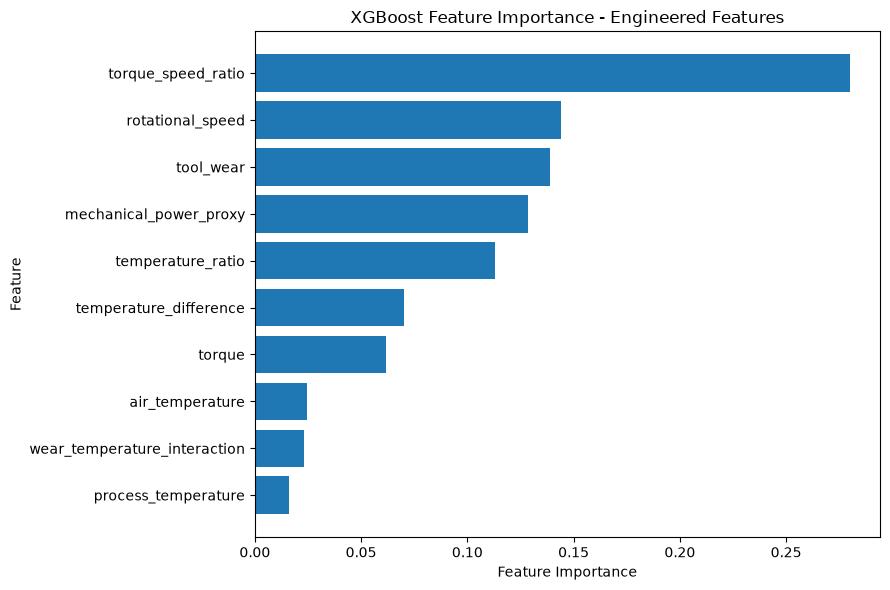

In [167]:
# Get feature importance
feature_importance_eng = pd.DataFrame({
    "Feature": X_train_eng_xgb.columns,
    "Importance": xgb_engineered.feature_importances_
})

# Sort from most to least important
feature_importance_eng = feature_importance_eng.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Add rank
feature_importance_eng.insert(
    0,
    "Rank",
    range(1, len(feature_importance_eng) + 1)
)

print("Feature Importance - Engineered XGBoost")
print("----------------------------------------")
print(feature_importance_eng)

# Plot
plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance_eng["Feature"],
    feature_importance_eng["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance - Engineered Features")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [168]:
import shap

In [169]:
import xgboost
import shap

print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)

XGBoost: 3.2.0
SHAP: 0.51.0


SHAP values shape: (2000, 10)
Test data shape: (2000, 10)


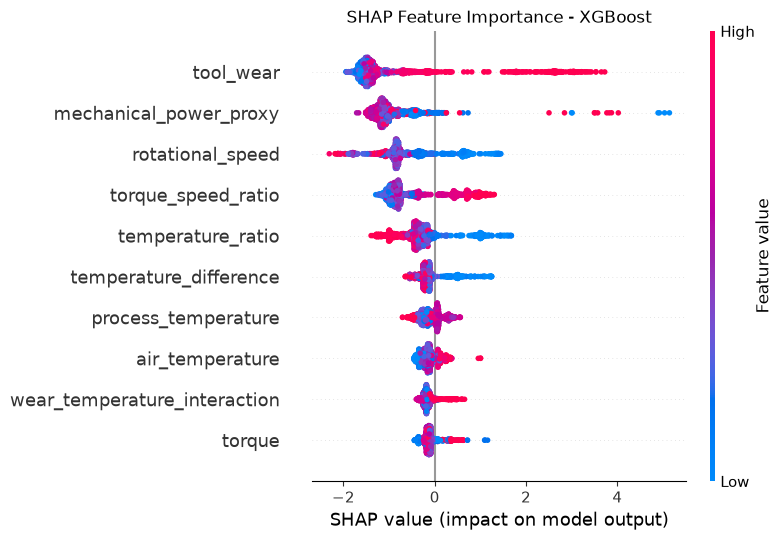

In [170]:
# Create SHAP TreeExplainer for our trained XGBoost model
explainer = shap.TreeExplainer(xgb_engineered)

# Calculate SHAP values for the test data
shap_values = explainer.shap_values(X_test_eng_xgb)

print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test_eng_xgb.shape)

# ============================================
# GLOBAL SHAP SUMMARY
# ============================================

plt.figure()

shap.summary_plot(
    shap_values,
    X_test_eng_xgb,
    show=False
)

plt.title("SHAP Feature Importance - XGBoost")
plt.tight_layout()
plt.show()

Actual Failure: 0
Failure Probability: 0.4863

Machine Sensor Values:
                                      2997
air_temperature                 300.500000
process_temperature             309.800000
rotational_speed               1345.000000
torque                           62.700000
tool_wear                       153.000000
temperature_difference            9.300000
mechanical_power_proxy        84331.500000
temperature_ratio                 1.030948
torque_speed_ratio                0.046617
wear_temperature_interaction   1422.900000


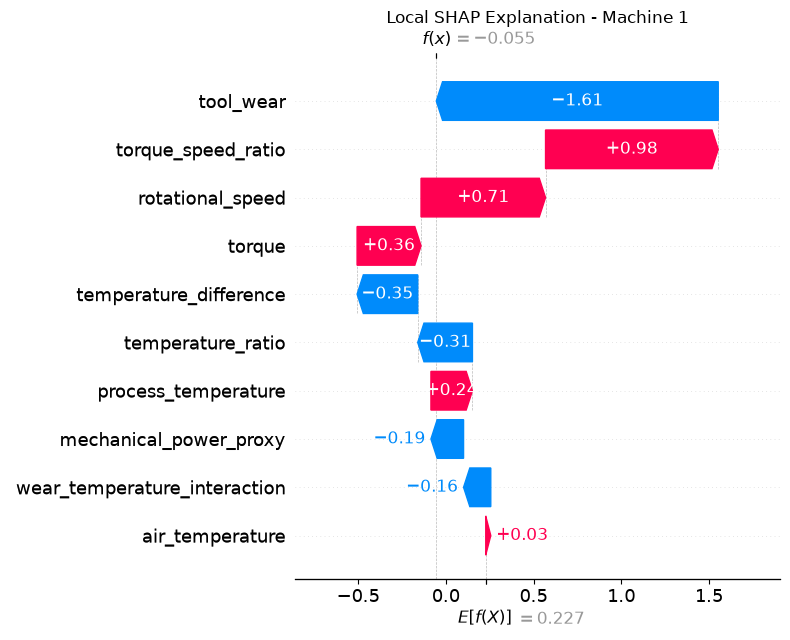

In [171]:
sample_index = 0

# Get the machine's feature values
sample = X_test_eng_xgb.iloc[[sample_index]]

# Get its actual failure label and predicted probability
actual_label = y_test_eng.iloc[sample_index]
failure_probability = xgb_engineered.predict_proba(sample)[0, 1]

print("Actual Failure:", actual_label)
print(f"Failure Probability: {failure_probability:.4f}")

print("\nMachine Sensor Values:")
print(sample.T)

# Calculate SHAP values for this single machine
sample_shap_values = explainer.shap_values(sample)

# Display local SHAP waterfall plot
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value,
    sample_shap_values[0],
    feature_names=sample.columns,
    features=sample.iloc[0].values,
    max_display=10,
    show=False
)

plt.title("Local SHAP Explanation - Machine 1")
plt.tight_layout()
plt.show()

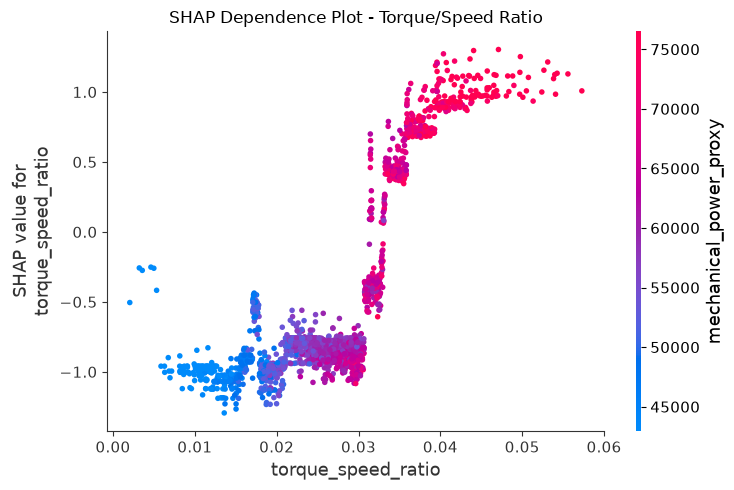

In [172]:
# Dependence plot for our most important engineered feature
shap.dependence_plot(
    "torque_speed_ratio",
    shap_values,
    X_test_eng_xgb,
    show=False
)

plt.title("SHAP Dependence Plot - Torque/Speed Ratio")
plt.tight_layout()
plt.show()

In [175]:
X_test_eng = X_test_eng.copy()

X_test_eng.columns = [
    "air_temperature",
    "process_temperature",
    "rotational_speed",
    "torque",
    "tool_wear",
    "temperature_difference",
    "mechanical_power_proxy",
    "temperature_ratio",
    "torque_speed_ratio",
    "wear_temperature_interaction"
]